In [1]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns  

In [2]:
df = pd.read_excel("netflix_customer_churn.csv.xlsx")
df.head()

,customer_id,age,gender,subscription_type,watch_hours,last_login_days,region,device,monthly_fee,churned,payment_method,number_of_profiles,avg_watch_time_per_day,favorite_genre
0,a9b75100-82a8-427a-a208-72f24052884a,51,Other,Basic,14.73,29,Africa,TV,8.99,1,Gift Card,1,0.49,Action
1,49a5dfd9-7e69-4022-a6ad-0a1b9767fb5b,47,Other,Standard,0.70,19,Europe,Mobile,13.99,1,Gift Card,5,0.03,Sci-Fi
2,4d71f6ce-fca9-4ff7-8afa-197ac24de14b,27,Female,Standard,16.32,10,Asia,TV,13.99,0,Crypto,2,1.48,Drama
3,d3c72c38-631b-4f9e-8a0e-de103cad1a7d,53,Other,Premium,4.51,12,Oceania,TV,17.99,1,Crypto,2,0.35,Horror
4,4e265c34-103a-4dbb-9553-76c9aa47e946,56,Other,Standard,1.89,13,Africa,Mobile,13.99,1,Crypto,2,0.13,Action


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   customer_id             5000 non-null   str    
 1   age                     5000 non-null   int64  
 2   gender                  5000 non-null   str    
 3   subscription_type       5000 non-null   str    
 4   watch_hours             5000 non-null   float64
 5   last_login_days         5000 non-null   int64  
 6   region                  5000 non-null   str    
 7   device                  5000 non-null   str    
 8   monthly_fee             5000 non-null   float64
 9   churned                 5000 non-null   int64  
 10  payment_method          5000 non-null   str    
 11  number_of_profiles      5000 non-null   int64  
 12  avg_watch_time_per_day  5000 non-null   float64
 13  favorite_genre          5000 non-null   str    
dtypes: float64(3), int64(4), str(7)
memory usage: 547.0

In [4]:
df.isnull().sum()

customer_id               0
age                       0
gender                    0
subscription_type         0
watch_hours               0
last_login_days           0
region                    0
device                    0
monthly_fee               0
churned                   0
payment_method            0
number_of_profiles        0
avg_watch_time_per_day    0
favorite_genre            0
dtype: int64

In [5]:
df.duplicated().sum()

np.int64(0)

In [6]:
df.shape

(5000, 14)

In [7]:
df.describe()

,age,watch_hours,last_login_days,monthly_fee,churned,number_of_profiles,avg_watch_time_per_day
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,43.847400,11.649450,30.089800,13.683400,0.503000,3.024400,0.874800
std,15.501128,12.014654,17.536078,3.692062,0.500041,1.415841,2.619824
min,18.000000,0.010000,0.000000,8.990000,0.000000,1.000000,0.000000
25%,30.000000,3.337500,15.000000,8.990000,0.000000,2.000000,0.110000
50%,44.000000,8.000000,30.000000,13.990000,1.000000,3.000000,0.290000
75%,58.000000,16.030000,45.000000,17.990000,1.000000,4.000000,0.720000
max,70.000000,110.400000,60.000000,17.990000,1.000000,5.000000,98.420000


# EDA

In [8]:
df.columns

Index(['customer_id', 'age', 'gender', 'subscription_type', 'watch_hours',
       'last_login_days', 'region', 'device', 'monthly_fee', 'churned',
       'payment_method', 'number_of_profiles', 'avg_watch_time_per_day',
       'favorite_genre'],
      dtype='str')

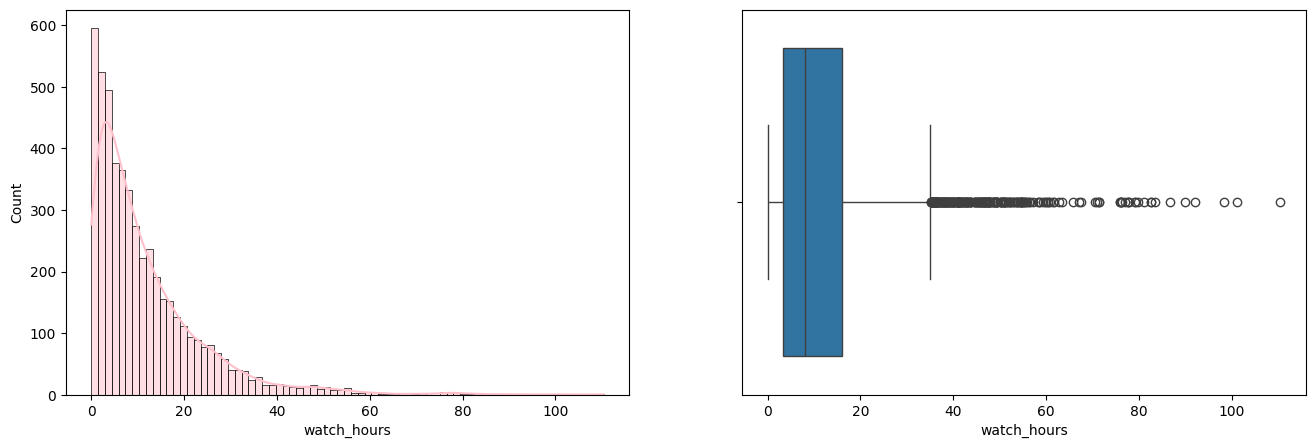

In [9]:
"""visualizing Feature Watch hours using histogram plot and boxplot to check the distribution of watch hour 
and to detect the outliers."""

plt.figure(figsize=(16,5))

plt.subplot(1,2,1)
sns.histplot(df['watch_hours'] , kde=True , color='Pink')

plt.subplot(1,2,2)
sns.boxplot(x = df['watch_hours'])

plt.show()

Interpretation : Watch hours has many outliers and it is right skewed 

In [10]:
df['watch_hours'].skew()


np.float64(2.2591953419514588)

In [11]:
""" Computed IQR and after calculating upper and lower fense retained the observations thay lie withing
that range and removed the outliers"""

percentile_25 = df['watch_hours'].quantile(0.25)
percentile_75 = df['watch_hours'].quantile(0.75)

IQR = (percentile_75 - percentile_25)
print(percentile_25,percentile_75)
print(IQR)

3.3375 16.03
12.6925


In [12]:
l_f = (percentile_25-(1.5*(IQR)))
print(l_f) 
u_f = (percentile_75+(1.5*(IQR)))
print(u_f)

-15.70125
35.06875


In [13]:
print((df['watch_hours'] > u_f).value_counts())

print((df['watch_hours'] < l_f).value_counts())

watch_hours
False    4762
True      238
Name: count, dtype: int64
watch_hours
False    5000
Name: count, dtype: int64


In [14]:
df = df[df['watch_hours'] < u_f]
df

,customer_id,age,gender,subscription_type,watch_hours,last_login_days,region,device,monthly_fee,churned,payment_method,number_of_profiles,avg_watch_time_per_day,favorite_genre
0,a9b75100-82a8-427a-a208-72f24052884a,51,Other,Basic,14.73,29,Africa,TV,8.99,1,Gift Card,1,0.49,Action
1,49a5dfd9-7e69-4022-a6ad-0a1b9767fb5b,47,Other,Standard,0.70,19,Europe,Mobile,13.99,1,Gift Card,5,0.03,Sci-Fi
2,4d71f6ce-fca9-4ff7-8afa-197ac24de14b,27,Female,Standard,16.32,10,Asia,TV,13.99,0,Crypto,2,1.48,Drama
3,d3c72c38-631b-4f9e-8a0e-de103cad1a7d,53,Other,Premium,4.51,12,Oceania,TV,17.99,1,Crypto,2,0.35,Horror
4,4e265c34-103a-4dbb-9553-76c9aa47e946,56,Other,Standard,1.89,13,Africa,Mobile,13.99,1,Crypto,2,0.13,Action
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4994,75532a22-9cd9-492c-8865-fa4ac7da2ec8,58,Other,Basic,10.90,22,Europe,TV,8.99,0,Credit Card,3,0.47,Action
4996,18779bcb-ba2b-41da-b751-e70b812061ec,67,Female,Basic,9.24,2,North America,Desktop,8.99,0,PayPal,3,3.08,Documentary
4997,3f32e8c5-615b-4a3b-a864-db2688f7834f,66,Male,Standard,16.55,49,South America,Desktop,13.99,1,Debit Card,2,0.33,Action
4998,7b0ad82d-6571-430e-90f4-906259e0e89c,59,Female,Basic,9.12,3,Europe,Laptop,8.99,0,Credit Card,4,2.28,Sci-Fi


<Axes: xlabel='watch_hours', ylabel='Count'>

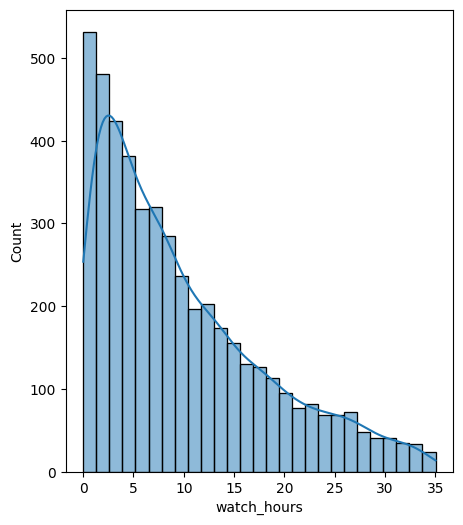

In [15]:
plt.figure(figsize=(5,6))
sns.histplot(x='watch_hours',kde=True,data=df)

Outliers from watch hours have been removed, because outliers could influence the model causing them to learn incorrect
relation between features and target variable.


<Figure size 500x400 with 0 Axes>

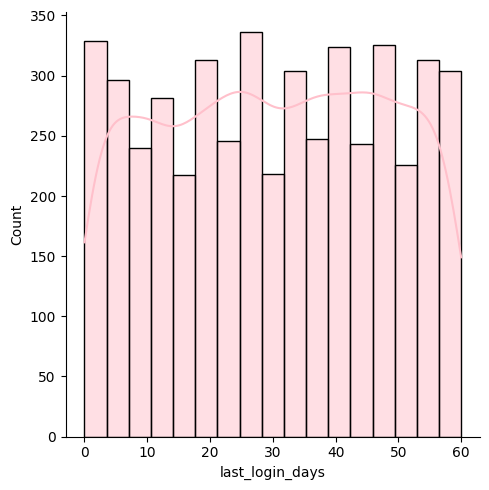

In [16]:
plt.figure(figsize=(5,4))
sns.displot(x=df['last_login_days'] , kde=True , color='Pink')

<Axes: xlabel='last_login_days'>

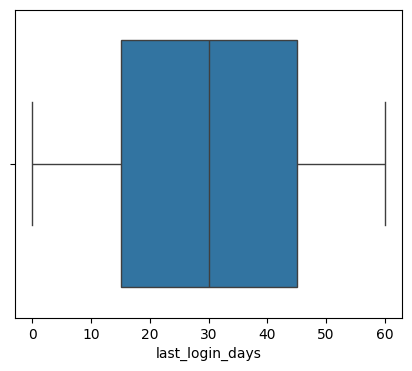

In [17]:
plt.figure(figsize=(5,4))
sns.boxplot(x=df['last_login_days'])

Interpreation : No outliers in last login days but not normally distributed.

In [18]:
df['churned'].value_counts(normalize=True)

churned
1    0.527719
0    0.472281
Name: proportion, dtype: float64

50.3% people are churned and 49.7% are not churned .

There are 50.3% of customers are churned and 49.7% are not churned .

Interpretation : the median for 0 is higher for 0(not churned) then 1 (churned)
customer who stayed generally have higher watch hour then the customer who left

Interpretation : Median for 0 is approx 20 days and median for 1 is approx 40 days
that means churned customer generally stayed inactive for longer days 

In [19]:
group = df.groupby('number_of_profiles')['churned'].value_counts(normalize=True)
group

number_of_profiles  churned
1                   1          0.607487
                    0          0.392513
2                   1          0.593395
                    0          0.406605
3                   1          0.613661
                    0          0.386339
4                   0          0.601488
                    1          0.398512
5                   0          0.571429
                    1          0.428571
Name: proportion, dtype: float64

C:\Users\SHREYA\AppData\Local\Temp\ipykernel_9880\3376434231.py:2: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.histplot(x='number_of_profiles',data=df,palette='pastel')


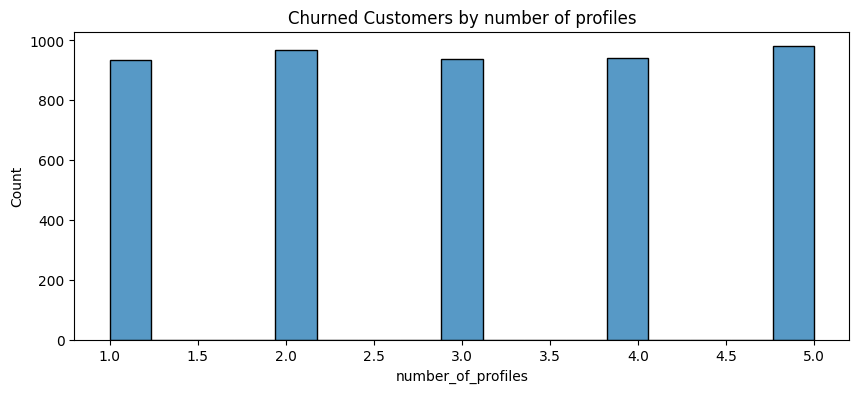

In [20]:
plt.figure(figsize=(10, 4))
sns.histplot(x='number_of_profiles',data=df,palette='pastel')
plt.title("Churned Customers by number of profiles")
plt.show()

Interpretation: Customer with 1 2 and 3 number of profiles has the most churned rate and 
                Customer with 4 and 5 profiles are less churned.

In [21]:
df.groupby('monthly_fee')['churned'].value_counts(normalize=True)

monthly_fee  churned
8.99         1          0.647505
             0          0.352495
13.99        0          0.520513
             1          0.479487
17.99        0          0.542928
             1          0.457072
Name: proportion, dtype: float64

<function matplotlib.pyplot.show(close=None, block=None)>

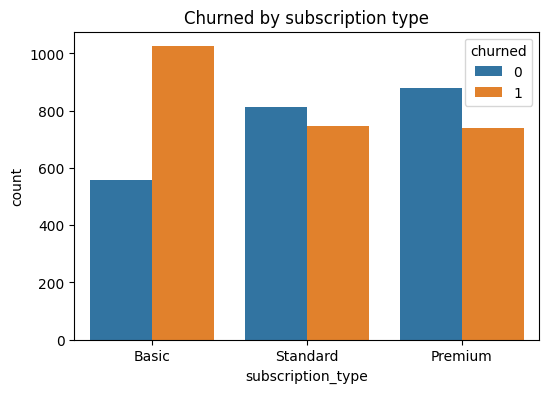

In [22]:
plt.figure(figsize=(6,4))
sns.countplot(x='subscription_type',hue = 'churned',data=df)
plt.title("Churned by subscription type")
plt.show

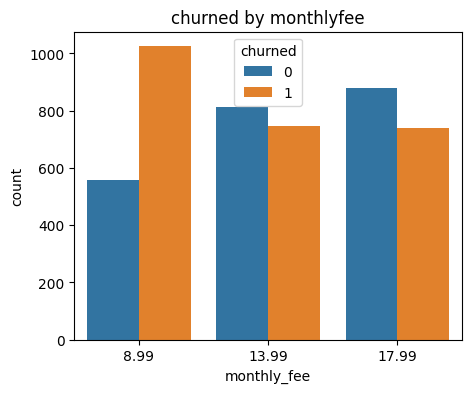

In [23]:
""" used countplot to visualize monthly fee and here monthly fee is categorical because there are only 3 types of monthly fee"""

plt.figure(figsize=(5,4))
sns.countplot(x='monthly_fee',hue='churned',data=df)
plt.title("churned by monthlyfee")
plt.show()

Interpretation : As subscription type and monthly fee give same information about churned . 
    Hence, we can drop subscription type feature to reduce redandant feature.

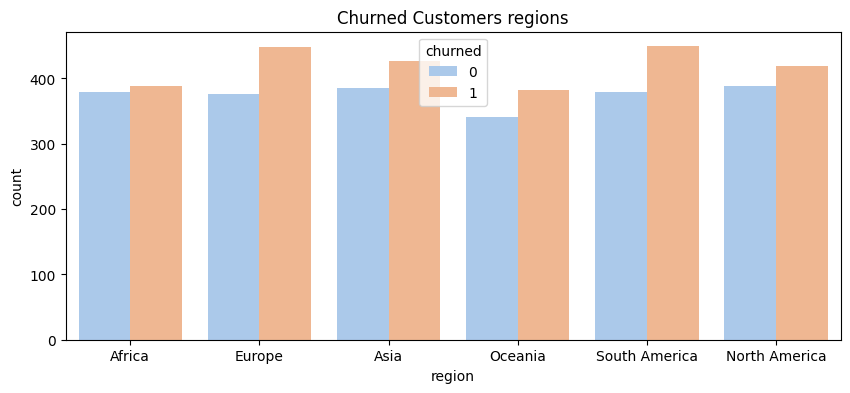

In [24]:
plt.figure(figsize=(10, 4))
sns.countplot(x='region',hue='churned',data=df,palette='pastel')
plt.title("Churned Customers regions")
plt.show()

Interpretation : Every region show equal contribution to churned and non-churned . Therefore , this feature has weak relationship
between target variable . And it was drop in preprocessing.

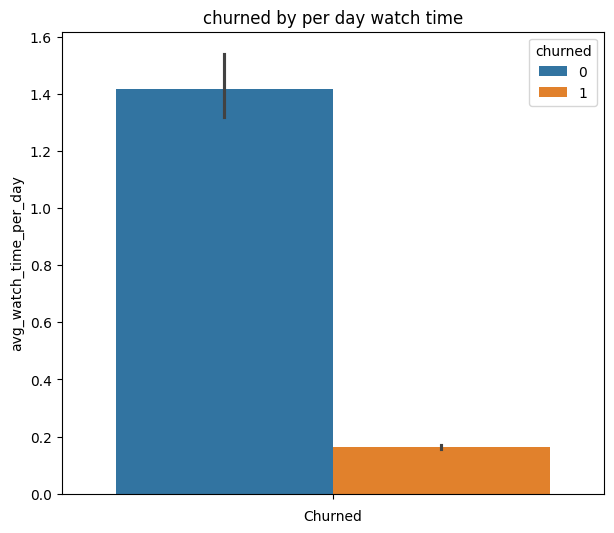

In [25]:
plt.figure(figsize=(7,6))
sns.barplot(y='avg_watch_time_per_day' , hue='churned',data=df)
plt.title("churned by per day watch time")
plt.xlabel("Churned")
plt.show()

Interpretation : Average watch hours per day show strong relation with target variable , making it potential feature for predicting target variable.

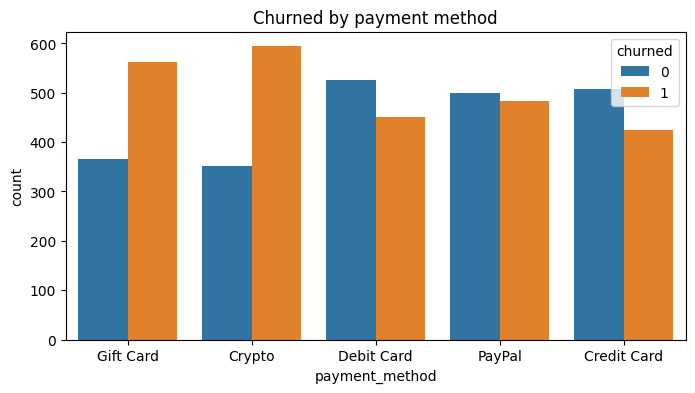

In [26]:
plt.figure(figsize=(8,4))
sns.countplot(x = 'payment_method', hue='churned',data=df)
plt.title("Churned by payment method")
plt.show()

Interpretation : Gift card and Crypto payment method show similar contribution to target variable and Paypal and Credit Card also exihibit almost
equal contribution to target variable And Customer with debit card have comparitively fewer  churned customer . 
    Therefore, payment method is associated with customer churned and can be usefull feature for target variable. 

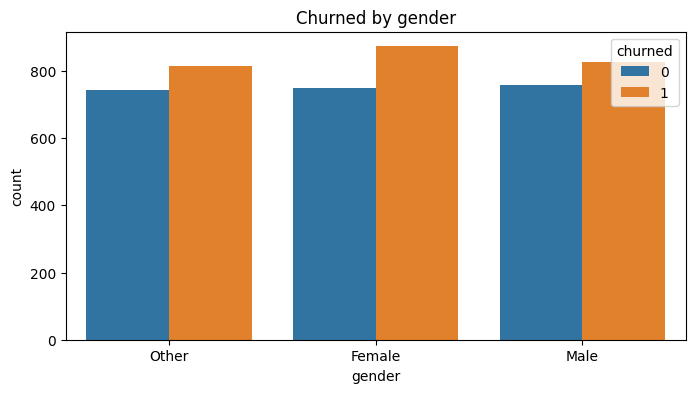

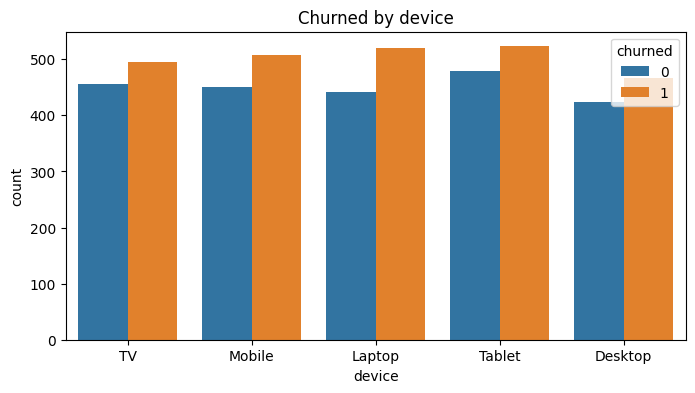

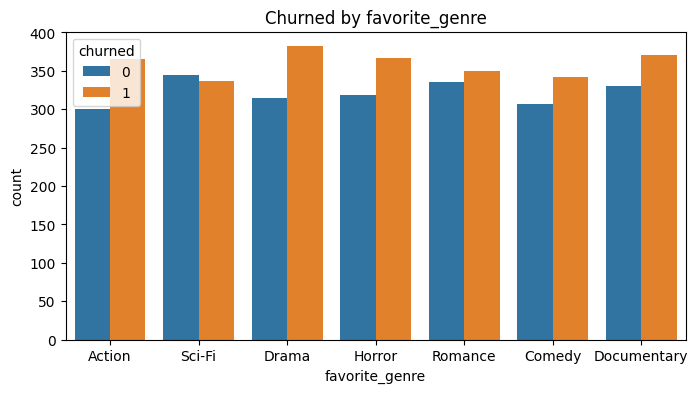

In [27]:
cols = ['gender','device','favorite_genre']

for col in cols:
    plt.figure(figsize=(8,4))
    sns.countplot(x=col,hue = 'churned',data=df)
    plt.title(f"Churned by {col}")
    

"Gender, Device, and Favorite Genre show a nearly equal distribution of churned and non-churned customers across their categories.
This suggests these features have a weak visible relationship with the target variable and 
may contribute less to predicting customer churn."
    "Therefore, these features were dropped during preprocessing as they appeared to have low predictive value for this dataset."

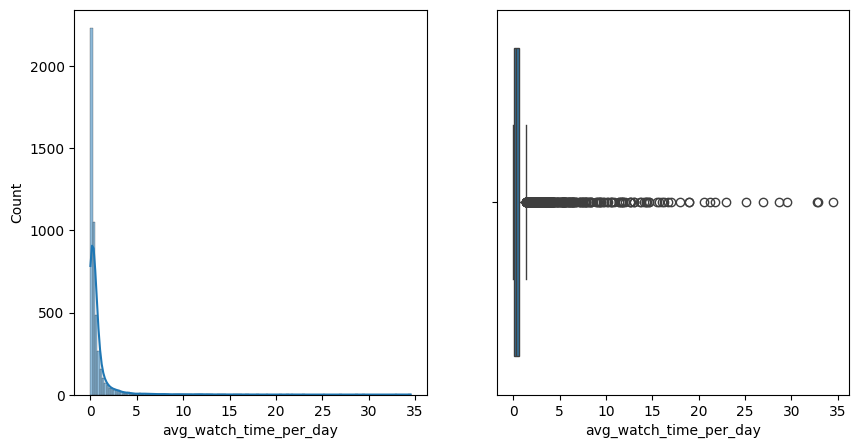

In [28]:
plt.figure(figsize=(10,5))

plt.subplot(1,2,1)
sns.histplot(x=df['avg_watch_time_per_day'],kde=True)

plt.subplot(1,2,2)
sns.boxplot(x=df['avg_watch_time_per_day'])

plt.show()

In [29]:
df['avg_watch_time_per_day'].skew()

np.float64(8.438787516452681)

In [30]:
# percentile_25 = df['avg_watch_time_per_day'].quantile(0.25)

# percentile_75 = df['avg_watch_time_per_day'].quantile(0.75)
# print(percentile_25,percentile_75)

# IQR = percentile_75 - percentile_25
# print(IQR)

In [31]:
# l_f = (percentile_25 - (1.5 * IQR))
# u_f = (percentile_75 + (1.5 * IQR))
# print(l_f,u_f)

In [32]:
# print((df['avg_watch_time_per_day'] > u_f).value_counts())
# print((df['avg_watch_time_per_day'] < l_f).value_counts())

In [33]:
# df = (df[df['avg_watch_time_per_day']] > u_f)
# df.astype(int)


In [34]:
df[['watch_hours','avg_watch_time_per_day']].corr()

,watch_hours,avg_watch_time_per_day
watch_hours,1.000000,0.326105
avg_watch_time_per_day,0.326105,1.000000


In [35]:
df['payment_method'].unique()

<StringArray>
['Gift Card', 'Crypto', 'Debit Card', 'PayPal', 'Credit Card']
Length: 5, dtype: str

# Data Preprocessing

In [36]:
df_clean = df.copy()
df_clean.head(1)


,customer_id,age,gender,subscription_type,watch_hours,last_login_days,region,device,monthly_fee,churned,payment_method,number_of_profiles,avg_watch_time_per_day,favorite_genre
0,a9b75100-82a8-427a-a208-72f24052884a,51,Other,Basic,14.73,29,Africa,TV,8.99,1,Gift Card,1,0.49,Action


In [37]:
# to_drop = df_clean['customer_id','age','gender','region','device','payment_method','favorite_genre']
df_clean = df_clean.drop(columns=(['customer_id','age','gender','region','device','favorite_genre','subscription_type','avg_watch_time_per_day']))
df_clean

,watch_hours,last_login_days,monthly_fee,churned,payment_method,number_of_profiles
0,14.73,29,8.99,1,Gift Card,1
1,0.70,19,13.99,1,Gift Card,5
2,16.32,10,13.99,0,Crypto,2
3,4.51,12,17.99,1,Crypto,2
4,1.89,13,13.99,1,Crypto,2
...,...,...,...,...,...,...
4994,10.90,22,8.99,0,Credit Card,3
4996,9.24,2,8.99,0,PayPal,3
4997,16.55,49,13.99,1,Debit Card,2
4998,9.12,3,8.99,0,Credit Card,4


In [38]:
print(df_clean['watch_hours'].std())
print(df_clean['watch_hours'].mean())

8.245591717070939
9.772097858042839


In [39]:
df_clean['payment_method'].value_counts()

payment_method
PayPal         982
Debit Card     976
Crypto         946
Credit Card    931
Gift Card      927
Name: count, dtype: int64

In [40]:
X_train = df_clean.drop(columns='churned')
X_train
Y_train = df_clean['churned']
Y_train

0       1
1       1
2       0
3       1
4       1
       ..
4994    0
4996    0
4997    1
4998    0
4999    1
Name: churned, Length: 4762, dtype: int64

In [41]:
from sklearn.model_selection import train_test_split

X_train,x_test,Y_train,y_test = train_test_split(X_train,Y_train ,test_size=0.2,random_state=42)
X_train

,watch_hours,last_login_days,monthly_fee,payment_method,number_of_profiles
2891,19.59,25,17.99,Credit Card,1
2670,1.97,39,8.99,Credit Card,3
661,8.99,53,13.99,Crypto,1
1860,3.77,12,8.99,Credit Card,2
2814,9.90,46,13.99,PayPal,5
...,...,...,...,...,...
4638,6.86,41,8.99,PayPal,4
496,5.47,36,8.99,Credit Card,1
3238,7.67,53,13.99,Crypto,3
3952,3.36,22,8.99,PayPal,3


In [42]:
X_train['payment_method'].unique()

<StringArray>
['Credit Card', 'Crypto', 'PayPal', 'Gift Card', 'Debit Card']
Length: 5, dtype: str

In [43]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder,MinMaxScaler
OneHotEncoder()
MinMaxScaler()

transformer = ColumnTransformer(transformers=[('tnf1',OneHotEncoder(sparse_output=False),['payment_method']),
                                              ('tnf2',MinMaxScaler(),['last_login_days','watch_hours'])],remainder='passthrough')

X_train_transformed = transformer.fit_transform(X_train)

In [44]:
x_test_transform = transformer.transform(x_test)

In [45]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression()
result = model.fit(X_train_transformed,Y_train)
result

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default sol

In [46]:
y_pred = model.predict(x_test_transform)
y_pred

array([0, 0, 0, 1, 1, 0, 0, 0, 0, 1, 1, 0, 1, 0, 0, 1, 1, 1, 1, 0, 0, 1,
       0, 1, 1, 1, 0, 0, 0, 1, 1, 1, 0, 1, 0, 1, 0, 0, 0, 1, 1, 0, 0, 1,
       1, 1, 0, 0, 1, 1, 1, 0, 1, 0, 0, 1, 0, 1, 1, 0, 1, 0, 1, 1, 1, 1,
       1, 0, 0, 1, 1, 1, 0, 0, 0, 0, 1, 1, 0, 0, 1, 0, 1, 0, 1, 0, 0, 1,
       1, 0, 1, 0, 0, 1, 0, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0,
       0, 1, 1, 0, 1, 1, 0, 0, 1, 0, 1, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0,
       1, 0, 1, 0, 0, 1, 0, 1, 1, 1, 1, 0, 1, 1, 1, 1, 0, 1, 1, 0, 1, 0,
       0, 1, 1, 1, 0, 1, 1, 0, 1, 1, 1, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1,
       0, 0, 1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 1, 1, 0, 1, 1,
       0, 0, 1, 1, 1, 1, 1, 1, 0, 0, 1, 0, 1, 1, 1, 0, 0, 0, 0, 1, 0, 0,
       1, 0, 1, 0, 0, 0, 1, 1, 1, 0, 0, 0, 0, 1, 0, 0, 1, 0, 1, 0, 0, 1,
       0, 1, 0, 1, 1, 0, 1, 1, 0, 1, 1, 0, 1, 0, 1, 0, 1, 0, 1, 1, 0, 1,
       1, 1, 0, 0, 0, 1, 0, 0, 1, 1, 1, 1, 0, 0, 0, 0, 0, 1, 1, 1, 0, 0,
       1, 1, 0, 1, 1, 1, 0, 1, 1, 0, 1, 0, 0, 1, 0,

In [47]:
from sklearn.metrics import accuracy_score,confusion_matrix,precision_score,recall_score, f1_score
accuracy = accuracy_score(y_test,y_pred,normalize=True)
print(accuracy)

confusion = confusion_matrix(y_test,y_pred)
print(confusion)

precision = precision_score(y_test,y_pred)
print(precision)

recall = recall_score(y_test,y_pred)
print(recall)

f1_score = f1_score(y_test,y_pred)
print(f1_score)

0.8803777544596013
[[377  62]
 [ 52 462]]
0.8816793893129771
0.8988326848249028
0.8901734104046243


In [48]:
y_train_pred = model.predict(X_train_transformed)
y_train_pred
accuracy = accuracy_score(Y_train,y_train_pred)
accuracy

0.8826463638750328

In [49]:
# from sklearn.model_selection import cross_val_score
# from sklearn.linear_model import LogisticRegression

# model = LogisticRegression()

# scores = cross_val_score(
#     model,
#     X_train_transformed,
#     Y_train,
#     cv=5,
#     scoring='accuracy'
# )

# print("Accuracy:", scores)
# print("Mean Accuracy:", scores.mean())

In [50]:
#Decision Tree 

from sklearn.tree import DecisionTreeClassifier

cls = DecisionTreeClassifier(criterion='entropy',max_depth=None,splitter= 'best',min_samples_split=100,random_state=42)

In [51]:
tree_model = cls.fit(X_train_transformed,Y_train)
tree_model

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'entropy'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",100
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsam

In [52]:
y_pred_tree = cls.predict(x_test_transform)

In [53]:
from sklearn.metrics import accuracy_score
tree_accuracy = accuracy_score(y_test,y_pred_tree,normalize=True)
tree_accuracy

0.9643231899265478

In [54]:
y_train_pred = cls.predict(X_train_transformed)

In [55]:
train_accuracy = accuracy_score(Y_train,y_train_pred)
train_accuracy

0.9708584930427934

In [56]:
parameters = {'criterion':['gini','entropy'],
              'max_depth':[1,2,3,4,5,6,7,8,None],
              'min_samples_split':[100,1000,2000]
}
print(parameters)

{'criterion': ['gini', 'entropy'], 'max_depth': [1, 2, 3, 4, 5, 6, 7, 8, None], 'min_samples_split': [100, 1000, 2000]}


In [57]:
from sklearn.model_selection import GridSearchCV
tree_grid = GridSearchCV(cls,param_grid=parameters,cv=5,n_jobs=-1)
tree_grid.fit(X_train_transformed,Y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",DecisionTreeC...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'criterion': ['gini', 'entropy'], 'max_depth': [1, 2, ...], 'min_samples_split': [100, 1000, ...]}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=

In [58]:
tree_grid.best_params_

{'criterion': 'entropy', 'max_depth': 7, 'min_samples_split': 100}

In [59]:
tree_grid.best_score_

np.float64(0.9645562373034513)

In [60]:
y_train_pred

array([0, 1, 1, ..., 1, 1, 0], shape=(3809,))

In [61]:
X_train_transformed.shape

(3809, 9)

In [62]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

y_pred = tree_model.predict(x_test_transform)

print("Accuracy :", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall   :", recall_score(y_test, y_pred))
print("F1 Score :", f1_score(y_test, y_pred))

Accuracy : 0.9643231899265478
Precision: 0.9597701149425287
Recall   : 0.9747081712062257
F1 Score : 0.9671814671814671


In [63]:
X_train_transformed.shape

(3809, 9)

In [64]:
# !pip install dtreeviz

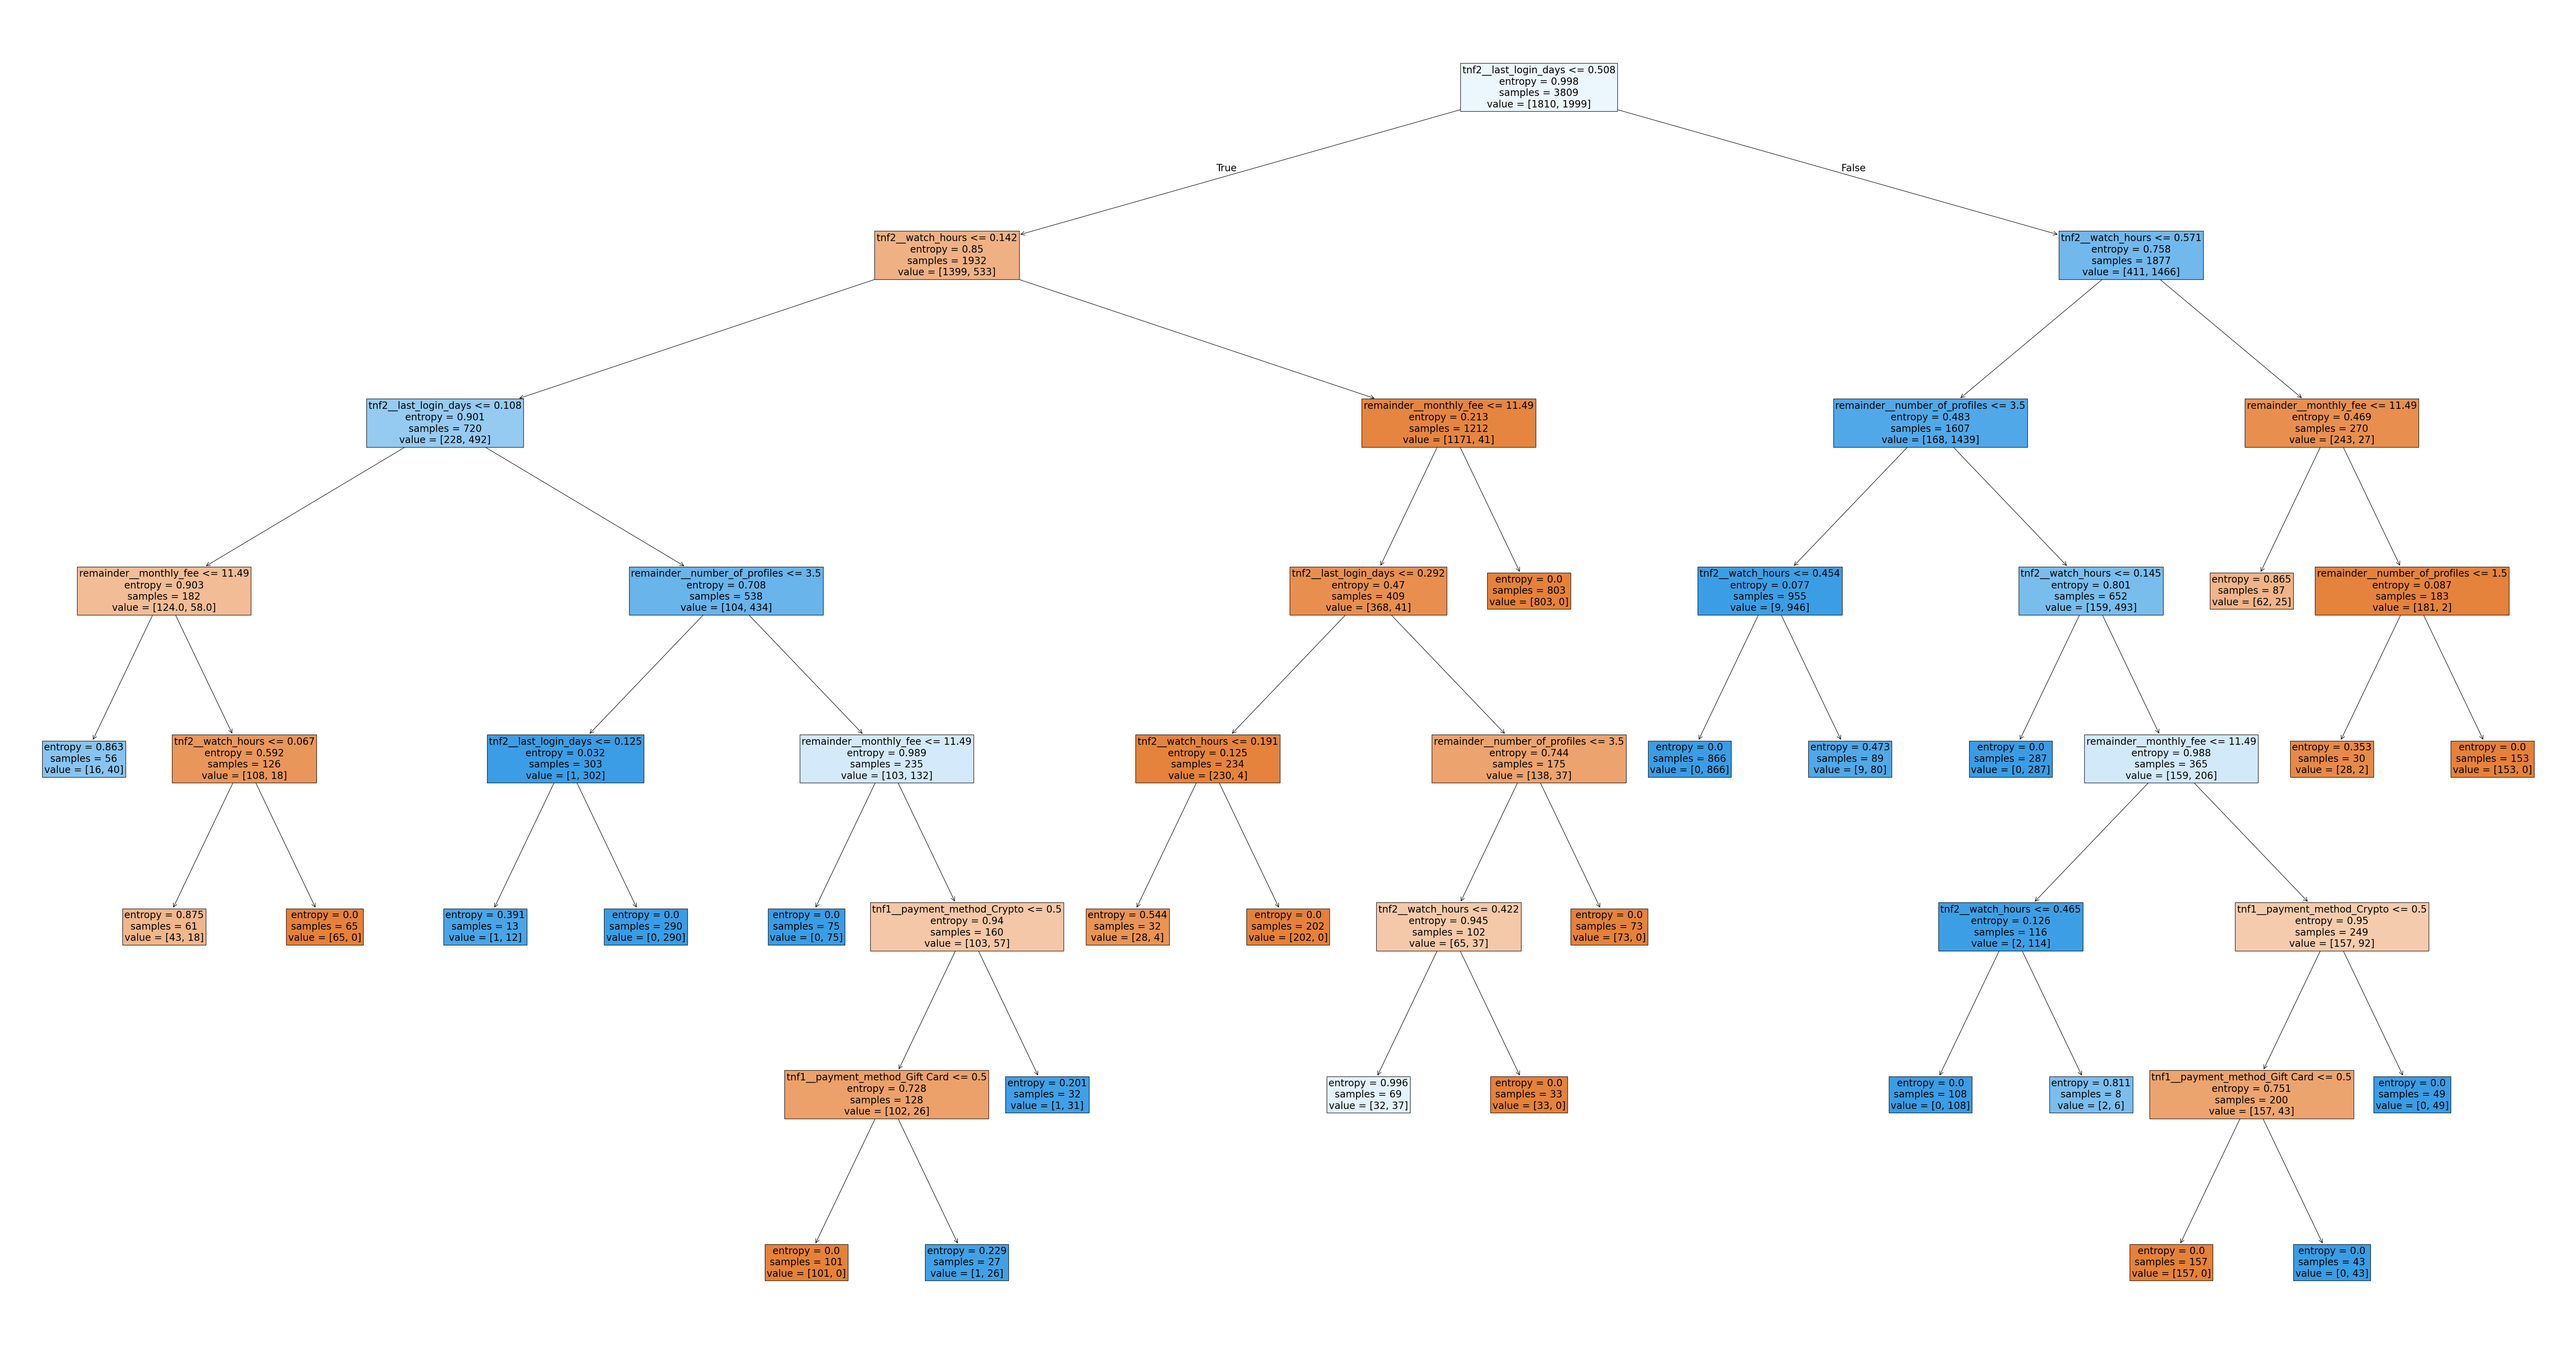

In [65]:
from sklearn.tree import plot_tree

plt.figure(figsize=(95,50))
plot_tree(cls,feature_names=
          ['tnf1__payment_method_Credit Card', 'tnf1__payment_method_Crypto',
       'tnf1__payment_method_Debit Card',
       'tnf1__payment_method_Gift Card', 'tnf1__payment_method_PayPal',
       'tnf2__last_login_days', 'tnf2__watch_hours',
       'remainder__monthly_fee', 'remainder__number_of_profiles'],filled=True,fontsize=20)
plt.show()

In [66]:
feature = transformer.get_feature_names_out()
feature

array(['tnf1__payment_method_Credit Card', 'tnf1__payment_method_Crypto',
       'tnf1__payment_method_Debit Card',
       'tnf1__payment_method_Gift Card', 'tnf1__payment_method_PayPal',
       'tnf2__last_login_days', 'tnf2__watch_hours',
       'remainder__monthly_fee', 'remainder__number_of_profiles'],
      dtype=object)

In [67]:
from sklearn.ensemble import  RandomForestClassifier
rf = RandomForestClassifier(n_estimators= 50,bootstrap=True,
                            criterion= 'gini',max_depth=5,min_samples_split=100,
                            max_samples=800,max_features=9,random_state=42)
rf_model = rf.fit(X_train_transformed,Y_train)
rf_model

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",50
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",5
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",100
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",9
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"max_samples max_samples: int or float, default=NoneIf bootstrap is True, the number of samples to draw from Xto train each base estimator.- If None (default), then draw `X.shape[0]` samples irrespective of `sample_weight`.- If int, then draw `max_samples` samples.- If float, then draw `max_samples * X.shape[0]` unweighted samples or `max_samples * sample_weight.sum()` weighted samples... versionadded:: 0.22.. versionchanged:: 1.9 Float `max_samples` is relative to `sample_weight.sum()` instead of `X.shape[0]` for weighted samples.",800
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the imp

In [68]:
y_rf_predict = rf_model.predict(x_test_transform)


In [69]:
rf_accuracy = accuracy_score(y_test,y_rf_predict)
rf_accuracy

0.8898216159496327

In [96]:
print("Accuracy :", accuracy_score(y_test, y_rf_predict))
print("Precision:", precision_score(y_test, y_rf_predict))
print("Recall   :", recall_score(y_test, y_rf_predict))
print("F1 Score :", f1_score(y_test, y_rf_predict))

Accuracy : 0.8898216159496327
Precision: 0.8738574040219378
Recall   : 0.9299610894941635
F1 Score : 0.9010367577756834


# Random search grid

In [70]:
n_estimators = [10,20,30,40,50]
max_fea = [8,9]
max_samples = [200,500,800,1000]
max_depth = [5,10]
min_sample_split = [100,300,500]
bootstrap = [True,False]

In [71]:
para_grid = {'n_estimators':n_estimators,
            'max_features':max_fea,
            'max_samples':max_samples, 
            'max_depth':max_depth, 
            'min_samples_split':min_sample_split,
            'bootstrap':bootstrap}
para_grid

{'n_estimators': [10, 20, 30, 40, 50],
 'max_features': [8, 9],
 'max_samples': [200, 500, 800, 1000],
 'max_depth': [5, 10],
 'min_samples_split': [100, 300, 500],
 'bootstrap': [True, False]}

In [72]:
from sklearn.model_selection import RandomizedSearchCV
rf_grid = RandomizedSearchCV(estimator=rf,
                            param_distributions=para_grid, 
                            cv=5,
                            verbose=2,n_jobs=-1)

In [73]:
rf_grid.fit(X_train_transformed,Y_train)

Fitting 5 folds for each of 10 candidates, totalling 50 fits


C:\Users\SHREYA\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\model_selection\_validation.py:489: FitFailedWarning: 
25 fits failed out of a total of 50.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
25 fits failed with the following error:
Traceback (most recent call last):
  File "C:\Users\SHREYA\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\model_selection\_validation.py", line 851, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "C:\Users\SHREYA\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\base.py", line 1403, in wrapper
    return fit_method(estimator, *args, **kwargs)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\SHREYA\Ap

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestC...ndom_state=42)
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'bootstrap': [True, False], 'max_depth': [5, 10], 'max_features': [8, 9], 'max_samples': [200, 500, ...], ...}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",2
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",10
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly

In [74]:
rf_grid.best_params_

{'n_estimators': 10,
 'min_samples_split': 100,
 'max_samples': 1000,
 'max_features': 8,
 'max_depth': 5,
 'bootstrap': True}

In [75]:
rf_grid.best_score_

np.float64(0.8918310966713918)

In [76]:
from sklearn.model_selection import GridSearchCV
grid = GridSearchCV(estimator=rf,param_grid=para_grid,cv=5,verbose=2,n_jobs=-1)

In [77]:
grid.fit(X_train_transformed,Y_train)

Fitting 5 folds for each of 480 candidates, totalling 2400 fits


C:\Users\SHREYA\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\model_selection\_validation.py:489: FitFailedWarning: 
1200 fits failed out of a total of 2400.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
1200 fits failed with the following error:
Traceback (most recent call last):
  File "C:\Users\SHREYA\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\model_selection\_validation.py", line 851, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "C:\Users\SHREYA\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\base.py", line 1403, in wrapper
    return fit_method(estimator, *args, **kwargs)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\SHR

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestC...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'bootstrap': [True, False], 'max_depth': [5, 10], 'max_features': [8, 9], 'max_samples': [200, 500, ...], ...}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",2
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_sel

In [78]:
grid.best_params_

{'bootstrap': True,
 'max_depth': 5,
 'max_features': 9,
 'max_samples': 800,
 'min_samples_split': 100,
 'n_estimators': 10}

In [79]:
grid.best_score_

np.float64(0.8973422178995036)

In [80]:
rf_grid.best_params_

{'n_estimators': 10,
 'min_samples_split': 100,
 'max_samples': 1000,
 'max_features': 8,
 'max_depth': 5,
 'bootstrap': True}

In [81]:
K_nearest = "a"
K_nearest

'a'

In [82]:
# !pip install tensorflow

In [83]:
import tensorflow
from tensorflow import keras
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense

In [84]:
model = Sequential()

model.add(Dense(3,activation='sigmoid',input_dim=9))
model.add(Dense(3,activation='sigmoid',input_dim=9))
model.add(Dense(1,activation='sigmoid'))

C:\Users\SHREYA\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [85]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 3)                   │              30 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 3)                   │              12 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 1)                   │               4 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 46 (184.00 B)

 Trainable params: 46 (184.00 B)

 Non-trainable params: 0 (0.00 B)

In [86]:
X_train_transformed.shape

(3809, 9)

In [87]:
model.compile(loss='binary_crossentropy',optimizer='Adam',metrics=['accuracy'])

In [88]:
model.fit(X_train_transformed,Y_train,epochs=20,validation_split=0.2)

Epoch 1/20
96/96 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - accuracy: 0.4778 - loss: 0.7172 - val_accuracy: 0.4646 - val_loss: 0.7038
Epoch 2/20
96/96 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.4811 - loss: 0.6961 - val_accuracy: 0.5157 - val_loss: 0.6939
Epoch 3/20
96/96 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.5323 - loss: 0.6920 - val_accuracy: 0.5381 - val_loss: 0.6912
Epoch 4/20
96/96 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.5274 - loss: 0.6903 - val_accuracy: 0.5328 - val_loss: 0.6895
Epoch 5/20
96/96 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.5218 - loss: 0.6889 - val_accuracy: 0.5367 - val_loss: 0.6883
Epoch 6/20
96/96 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.5271 - loss: 0.6875 - val_accuracy: 0.5407 - val_loss: 0.6869
Epoch 7/20
96/96 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.5622 - loss: 0.6861 - val_accuracy: 0.5394 - val_loss: 0.6851
Epoch 8/20
96/96 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.5310 - loss: 0.6842 - val_accuracy: 0.5525 - val_loss

In [89]:
model.layers[1].get_weights()

[array([[ 0.6154237 ,  0.6801684 , -0.40444094],
        [-0.6701676 ,  0.66846246,  0.11130037],
        [ 1.9198433 , -0.52577347, -0.97195464]], dtype=float32),
 array([-0.25578067,  0.43645763,  0.3066993 ], dtype=float32)]

In [90]:
y_log = model.predict(x_test_transform)

30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step


In [99]:
y_pred1 = np.where(y_log>0.5,1,0)

In [100]:
accuracy_score(y_test,y_pred)

0.8268625393494229

In [101]:
print("Accuracy :", accuracy_score(y_test, y_pred1))
print("Precision:", precision_score(y_test, y_pred1))
print("Recall   :", recall_score(y_test, y_pred1))
print("F1 Score :", f1_score(y_test, y_pred1))

Accuracy : 0.8268625393494229
Precision: 0.7855973813420621
Recall   : 0.933852140077821
F1 Score : 0.8533333333333334


In [94]:
df_clean['churned'].value_counts()

churned
1    2513
0    2249
Name: count, dtype: int64

In [95]:
df['churned'].mean()

np.float64(0.5277194456110877)